# Preferences in two dimensions

Section 7 of `preference_demo.ipynb`, moved here to keep that notebook small. The setup cell is the same; `prob_first_better` is the function of its section 6 (median and $\pm 2$ sd band of $P(x \succ y)$). "6b" below refers to the heatmap of that notebook.

In [ ]:
import sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.stats import norm, spearmanr

for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "BOproj").is_dir():
        sys.path.insert(0, str(folder))
        break

from BOproj.benchmarks import ROSEN_BOUNDS, u_polynomial
from BOproj.bo_loop import initial_design
from BOproj.gp import PreferenceGP

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100
utility = u_polynomial                                    # accept the disc of radius 0.8 around (-1, 1)


class NoisyPairwiseLabeler:
    """DM with Gaussian noise on each utility: a wins iff u(a) + noise_a > u(b) + noise_b, noise ~ N(0, sigma^2)."""

    def __init__(self, utility, sigma, seed=0):
        self.utility, self.sigma, self.rng = utility, sigma, np.random.default_rng(seed)

    def __call__(self, xa, xb):
        noise = self.sigma * self.rng.standard_normal((2, len(xa)))
        return self.utility(xa) + noise[0] > self.utility(xb) + noise[1]


def make_comparisons(sigma, n_comparisons, n_designs=40, seed=27):
    """The DM compares n_comparisons random pairs among n_designs lhs designs."""
    designs = initial_design(ROSEN_BOUNDS, n_designs, "lhs", seed=seed)
    rng = np.random.default_rng(seed)
    first = rng.integers(0, n_designs, n_comparisons)
    second = (first + rng.integers(1, n_designs, n_comparisons)) % n_designs
    first_wins = NoisyPairwiseLabeler(utility, sigma, seed=seed)(designs[first], designs[second])
    return designs[first], designs[second], first_wins


def fit(xa, xb, first_wins):
    return PreferenceGP(bounds=ROSEN_BOUNDS, link="probit").fit(xa, xb, first_wins)


line = np.linspace(-2, 2, 70)
map_x1, map_x2 = np.meshgrid(line, line)
X_map = np.c_[map_x1.ravel(), map_x2.ravel()] #X_map is just a grid of points in the bounds of the Rosenbrock function, used for visualization of the learned utility function.
test_X = initial_design(ROSEN_BOUNDS, 1000, "lhs", seed=99)


def draw(axis, values, title, cmap="viridis", levels=20):
    shown = axis.contourf(map_x1, map_x2, values.reshape(map_x1.shape), levels, cmap=cmap)
    axis.figure.colorbar(shown, ax=axis)
    axis.contour(map_x1, map_x2, utility(X_map).reshape(map_x1.shape), [0], colors="w", linestyles="--")
    axis.set_title(title)
    axis.set_aspect("equal")

In [ ]:
def prob_first_better(gp, xa, xb):  
    """For pairs (xa[j], xb[j]): the median Phi(m / sqrt 2) of the latent probability Phi((g(xa) - g(xb)) / sqrt 2), and its
    band Phi((m -+ 2 s) / sqrt 2), where m, s are the mean and sd of the latent difference g(xa) - g(xb)."""
    pairs = torch.as_tensor(np.stack([xa, xb], axis=1), dtype=torch.float64)           # (n, 2, 1)
    posterior = gp.model.posterior(pairs)
    mean, cov = posterior.mean.squeeze(-1).detach(), posterior.mvn.covariance_matrix.detach()
    diff_mean = (mean[:, 0] - mean[:, 1]).numpy()
    diff_var = (cov[:, 0, 0] + cov[:, 1, 1] - 2 * cov[:, 0, 1]).clamp_min(0).numpy()
    diff_sd = np.sqrt(diff_var)
    return (norm.cdf(diff_mean / np.sqrt(2)),
        norm.cdf((diff_mean - 2 * diff_sd) / np.sqrt(2)), norm.cdf((diff_mean + 2 * diff_sd) / np.sqrt(2)))


## 7. Two dimensions

A pair of 2-d designs is 4-d, so two slices: 7a fixes $y$ and lets $x$ move over the whole box; 7b lets $x$ and $y$ both move along one line, which gives the heatmap of 6b. Polynomial utility, noise level x number of comparisons. The compared designs are points of one 40-point Latin hypercube. **Sure** = the $\pm 2$ sd band of $P(x \succ y)$ entirely above 0.9 or below 0.1 (black outline).

### 7a. Fixed $y = (0, 0)$ (triangle), $x$ over the box

Each arrow goes from the loser to the winner of one comparison (red = contradicts the true utility). Left column: the true probability for the noisy DM. The white dashed line is $u = 0$.

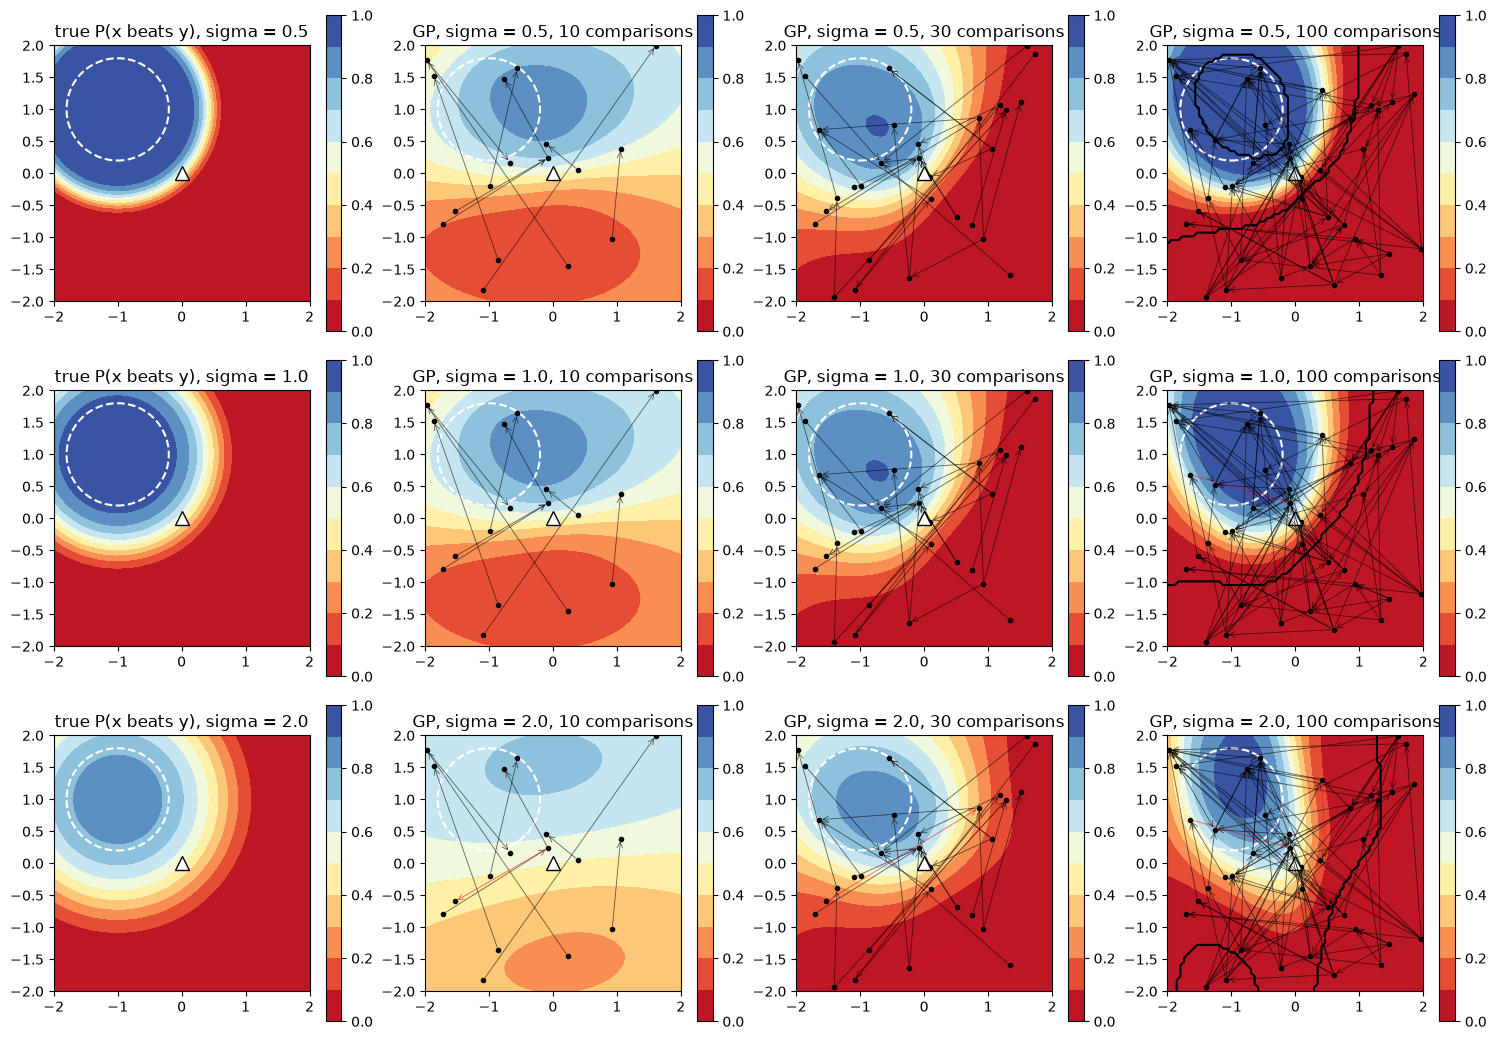

In [ ]:
reference_2d = np.array([[0.0, 0.0]])
sigmas_2d, counts_2d = (0.5, 1.0, 2.0), (10, 30, 100)
fits_2d = {}
for sigma in sigmas_2d:
    for n in counts_2d:
        xa, xb, a_wins = make_comparisons(sigma, n)
        gp = fit(xa, xb, a_wins)
        fits_2d[sigma, n] = (xa, xb, a_wins, gp)


def overlay(axis, xa, xb, a_wins):
    winner, loser = np.where(a_wins[:, None], xa, xb), np.where(a_wins[:, None], xb, xa)
    wrong = utility(winner) < utility(loser)
    for w, l, bad in zip(winner, loser, wrong):
        axis.annotate("", xy=w, xytext=l, arrowprops=dict(arrowstyle="->", color="red" if bad else "k", lw=0.6, alpha=0.6))
    axis.plot(*np.unique(np.r_[xa, xb], axis=0).T, "o", color="k", ms=3)
    axis.plot(*reference_2d[0], "k^", ms=10, mfc="w")
    axis.set(xlim=(-2, 2), ylim=(-2, 2))


fig, axes = plt.subplots(len(sigmas_2d), len(counts_2d) + 1, figsize=(15, 10.5))
for row, sigma in zip(axes, sigmas_2d):
    truth = norm.cdf((utility(X_map) - utility(reference_2d)) / (np.sqrt(2) * sigma))
    draw(row[0], truth, f"true P(x beats y), sigma = {sigma}", "RdYlBu", np.linspace(0, 1, 11))
    row[0].plot(*reference_2d[0], "k^", ms=10, mfc="w")
    for axis, n in zip(row[1:], counts_2d):
        xa, xb, a_wins, gp = fits_2d[sigma, n]
        mid, low, high = prob_first_better(gp, X_map, np.repeat(reference_2d, len(X_map), 0))
        draw(axis, mid, f"GP, sigma = {sigma}, {n} comparisons", "RdYlBu", np.linspace(0, 1, 11))
        axis.contour(map_x1, map_x2, ((low > 0.9) | (high < 0.1)).reshape(map_x1.shape).astype(float), [0.5], colors="k", linewidths=1.5)
        overlay(axis, xa, xb, a_wins)
plt.tight_layout()
plt.show()

### 7b. $x = (t, 1)$ and $y = (s, 1)$ both on the line $x_2 = 1$ (through the middle of the disc)

Each point of a panel is one pair of designs: $t$ says where $x$ is on the line, $s$ where $y$ is. Colour: $P(x \succ y)$, blue when $x$ is preferred.

* **Grey dotted lines:** pairs with the same true utility. $s = t$ is a design against itself; $s = -t - 2$ pairs two designs at the same distance from the centre $-1$ of the disc.
* **Black curves:** edge of the **sure** region, where the $\pm 2$ sd band of $P(x \succ y)$ is entirely above 0.9 or below 0.1. They look like hyperbolas because on this line $u(x) - u(y) = (s - t)(s + t + 2) / 0.64$, whose level sets are hyperbolas around those two dotted lines.
* **Dots:** the DM's actual comparisons with both designs within 0.5 of the line, at ($x_1$ of the first design, $x_1$ of the second). Blue: the first won, red: the second won. The GP also uses all the other comparisons, which are off this slice.

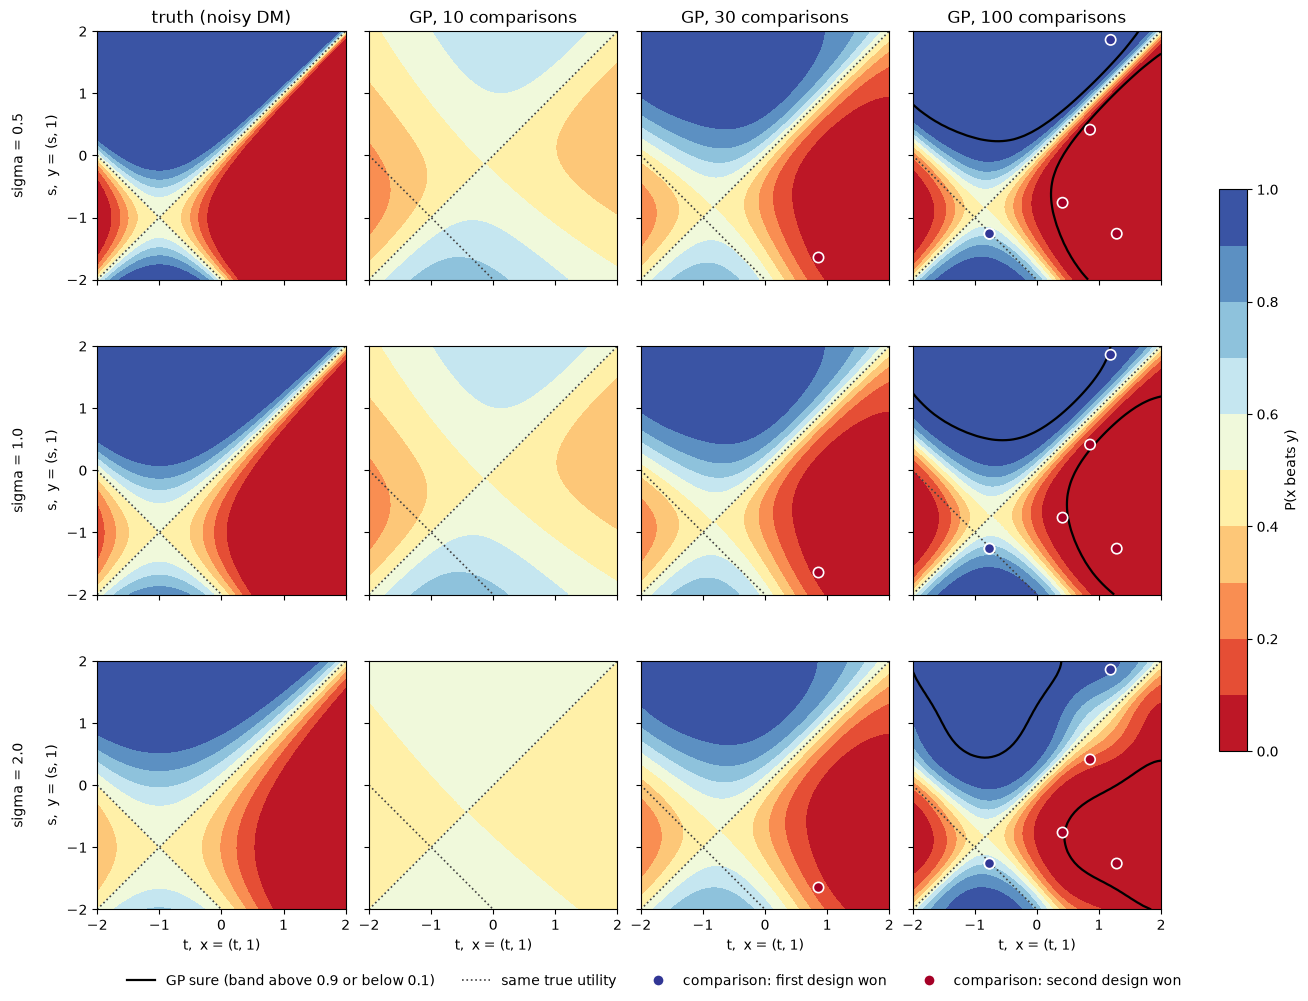

In [ ]:
line_t = np.linspace(-2, 2, 70)
slice_t, slice_s = np.meshgrid(line_t, line_t)
x_on_line = np.c_[slice_t.ravel(), np.ones(slice_t.size)]
y_on_line = np.c_[slice_s.ravel(), np.ones(slice_s.size)]
probability_levels = np.linspace(0, 1, 11)
line_half_width = 0.5                                     # a comparison is drawn if both designs are this close to x2 = 1
first_won_colour, second_won_colour = "#313695", "#a50026"


def draw_slice(axis, probabilities):
    """Filled map of P(x beats y) over (t, s), with the pairs of equal true utility dotted."""
    shown = axis.contourf(slice_t, slice_s, probabilities, probability_levels, cmap="RdYlBu", vmin=0, vmax=1)
    axis.plot([-2, 2], [-2, 2], ":", color="0.25", lw=1.2)
    axis.plot([-2, 0], [0, -2], ":", color="0.25", lw=1.2)
    axis.set(aspect="equal", xticks=[-2, -1, 0, 1, 2], yticks=[-2, -1, 0, 1, 2])
    return shown


fig, axes = plt.subplots(len(sigmas_2d), len(counts_2d) + 1, figsize=(13, 10), sharex=True, sharey=True, layout="constrained")
for row, sigma in zip(axes, sigmas_2d):
    truth = norm.cdf((utility(x_on_line) - utility(y_on_line)) / (np.sqrt(2) * sigma)).reshape(slice_t.shape)
    shown = draw_slice(row[0], truth)
    row[0].set_ylabel(f"sigma = {sigma}\n\ns,  y = (s, 1)")
    for axis, n in zip(row[1:], counts_2d):
        xa, xb, a_wins, gp = fits_2d[sigma, n]
        mid, low, high = (a.reshape(slice_t.shape) for a in prob_first_better(gp, x_on_line, y_on_line))
        draw_slice(axis, mid)
        axis.contour(slice_t, slice_s, low, [0.9], colors="k", linewidths=1.6)
        axis.contour(slice_t, slice_s, high, [0.1], colors="k", linewidths=1.6)
        near_line = (abs(xa[:, 1] - 1) < line_half_width) & (abs(xb[:, 1] - 1) < line_half_width)
        axis.scatter(xa[near_line, 0], xb[near_line, 0], s=55, edgecolors="w", linewidths=1.2, zorder=3,
                     c=np.where(a_wins[near_line], first_won_colour, second_won_colour))
for axis, title in zip(axes[0], ["truth (noisy DM)"] + [f"GP, {n} comparisons" for n in counts_2d]):
    axis.set_title(title)
for axis in axes[-1]:
    axis.set_xlabel("t,  x = (t, 1)")
fig.colorbar(shown, ax=axes, shrink=0.6, label="P(x beats y)", ticks=np.linspace(0, 1, 6))
legend_entries = [plt.Line2D([], [], color="k", lw=1.6, label="GP sure (band above 0.9 or below 0.1)"),
                  plt.Line2D([], [], color="0.25", ls=":", lw=1.2, label="same true utility"),
                  plt.Line2D([], [], ls="", marker="o", mfc=first_won_colour, mec="w", ms=8, label="comparison: first design won"),
                  plt.Line2D([], [], ls="", marker="o", mfc=second_won_colour, mec="w", ms=8, label="comparison: second design won")]
fig.legend(handles=legend_entries, loc="outside lower center", ncol=4, frameon=False)
plt.show()

### 7c. Checking $P(x \succ y) = \Phi\big(m / \sqrt{2 + v}\big)$

$m$, $v$: posterior mean and variance of $g(x) - g(y)$. $v$ is computed by the GP from the data, it is not a parameter; the 2 is the comparison noise fixed by the probit likelihood.

Three checks on random pairs: (1) the maps show the median $\Phi(m/\sqrt2)$ of the latent probability, while `prob_better_torch` uses the formula above; (2) the formula matches sampling $g$ from the posterior and adding the noise; (3) against the true probabilities of the noisy DM, compared with leaving out $v$ or the noise, and with replacing the 2 by another constant $c$. Error: mean KL divergence from the true answer probabilities (0 = perfect).

In [ ]:
from scipy.special import rel_entr

n_test_pairs = 3000
test_first = initial_design(ROSEN_BOUNDS, n_test_pairs, "lhs", seed=92)
test_second = initial_design(ROSEN_BOUNDS, n_test_pairs, "lhs", seed=27)
noise_constants = np.geomspace(0.125, 32, 9)


def latent_difference(gp, xa, xb):
    """Posterior mean and variance of g(xa) - g(xb), pair by pair."""
    pairs = torch.as_tensor(np.stack([xa, xb], axis=1), dtype=torch.float64)
    posterior = gp.model.posterior(pairs)
    mean, covariance = posterior.mean.squeeze(-1).detach(), posterior.mvn.covariance_matrix.detach()
    return (mean[:, 0] - mean[:, 1]).numpy(), (covariance[:, 0, 0] + covariance[:, 1, 1] - 2 * covariance[:, 0, 1]).clamp_min(0).numpy()


def mean_kl_from_truth(true_probability, predicted):
    predicted = np.clip(predicted, 1e-12, 1 - 1e-12)
    return np.mean(rel_entr(true_probability, predicted) + rel_entr(1 - true_probability, 1 - predicted))


def true_answer_probability(sigma):
    return norm.cdf((utility(test_first) - utility(test_second)) / (np.sqrt(2) * sigma))


# 1. the maps show the median of the latent probability, Phi(m / sqrt 2); the formula is what prob_better_torch uses
example_gp = fits_2d[1.0, 30][3]
difference_mean, difference_var = latent_difference(example_gp, test_first, test_second)
formula = norm.cdf(difference_mean / np.sqrt(2 + difference_var))
references = np.repeat(reference_2d, n_test_pairs, 0)
reference_mean, reference_var = latent_difference(example_gp, test_first, references)
print("largest gap, Phi(m / sqrt 2) vs prob_first_better (maps):", np.abs(norm.cdf(difference_mean / np.sqrt(2)) - prob_first_better(example_gp, test_first, test_second)[0]).max())
print("largest gap, formula vs PreferenceGP.prob_better_torch:", np.abs(norm.cdf(reference_mean / np.sqrt(2 + reference_var))
                                                                         - example_gp.prob_better_torch(test_first, reference_2d[0]).detach().numpy()).max())

# 2. the formula against sampling: draw g(x), g(y) jointly, add the DM's noise, count how often x wins
n_sampled_pairs, n_samples = 300, 20000
torch.manual_seed(0)
pairs = torch.as_tensor(np.stack([test_first[:n_sampled_pairs], test_second[:n_sampled_pairs]], axis=1), dtype=torch.float64)
utility_samples = example_gp.model.posterior(pairs).rsample(torch.Size([n_samples])).squeeze(-1).detach().numpy()
answer_noise = np.random.default_rng(0).standard_normal(utility_samples.shape)
sampled_probability = np.mean((utility_samples + answer_noise)[:, :, 0] > (utility_samples + answer_noise)[:, :, 1], axis=0)
print(f"largest gap, formula vs sampling ({n_samples} draws):", np.abs(formula[:n_sampled_pairs] - sampled_probability).max())

# 3. against the true DM
print(f"\n{'sigma':>5s} {'n':>4s}   error of:  m/sqrt(2+v)   m/sqrt(2) [no v]   m/sqrt(v) [no noise]")
fig, axes = plt.subplots(1, len(sigmas_2d), figsize=(13, 3.8), sharey=True, layout="constrained")
for axis, sigma in zip(axes, sigmas_2d):
    truth = true_answer_probability(sigma)
    for n in counts_2d:
        difference_mean, difference_var = latent_difference(fits_2d[sigma, n][3], test_first, test_second)
        errors = [mean_kl_from_truth(truth, norm.cdf(difference_mean / np.sqrt(denominator)))
                  for denominator in (2 + difference_var, 2 * np.ones(n_test_pairs), difference_var + 1e-12)]
        print(f"{sigma:5.1f} {n:4d}   {errors[0]:21.3f} {errors[1]:18.3f} {errors[2]:22.3f}")
        errors_by_constant = [mean_kl_from_truth(truth, norm.cdf(difference_mean / np.sqrt(c + difference_var))) for c in noise_constants]
        shown, = axis.plot(noise_constants, errors_by_constant, "o-", ms=4, label=f"{n} comparisons")
        axis.plot(noise_constants[np.argmin(errors_by_constant)], np.min(errors_by_constant), "o", ms=11, mfc="none", color=shown.get_color())
    axis.axvline(2, color="k", ls=":", lw=1)
    axis.set(xscale="log", xlabel="c in m / sqrt(c + v)", title=f"sigma = {sigma}")
axes[0].set_ylabel("error against the true DM (KL)")
axes[0].legend(fontsize=8)
plt.show()